# Segmentación de clientes Samsung en T1 — caracterización del conjunto TRAIN

Este notebook construye y describe los segmentos de **los clientes del conjunto TRAIN de Pogit**, utilizando exclusivamente características transaccionales observadas en la ventana **T1**. **No requiere ni utiliza W_test.**

**Dos conceptos distintos:** T1 es la ventana de tiempo de las compras; TRAIN identifica el subconjunto de clientes de la cohorte del modelo de regresión. El archivo de entrada es `W_train{TAG}.csv` (`matricees_data/data/matrices`). La inferencia y los perfiles se refieren a esos clientes, no a todos los consumidores de la base Amazon.

**Relación con los cuatro análisis anteriores:** exploración de A/B/C y K, sensibilidad al preprocesamiento, estabilidad ante submuestreo e inicializaciones, y Hopkins/Gap/referencias. No se declara un ganador de forma automática: se comparan los seis candidatos en TRAIN y después se fija explícitamente el elegido.

**Reglas metodológicas:**
- `response_id` identifica clientes, pero no entra al cálculo de distancias.
- Solo las variables numéricas transaccionales de T1 seleccionadas en A/B/C entran a K-Means. Las seis variables se usan para caracterizar todos los candidatos.
- W procede de R **ya winsorizada**, antes de la selección y escalado de Pogit. No se vuelve a winsorizar ni se emplea T2 como variable de agrupamiento.
- Escalado Z-score con desviación muestral (`ddof=1`) calculado sobre TRAIN. K-Means: semilla `123`, `n_init=30`, `max_iter=400`.
- La cohorte de Pogit se filtró previamente usando la exclusión de gasto Samsung T2 mayor que USD 5.000: esto afecta *quién entra en el análisis* aunque no se use T2 para formar grupos. Por ello, la caracterización es retrospectiva de la muestra de Pogit.

**Uso:** primero `ETAPA = "comparar"` para comparar perfiles. Después de justificar la elección con métricas y perfiles, cambiar a `ETAPA = "finalizar"` y fijar `MODELO_ELEGIDO`. Los clústeres se numeran `1..K` sin orden comercial implícito.


## 0. Configuración única

El umbral `MIN_MONETARY_T1` y el TAG se definen en `config_matrices.py`; la matriz se lee de `data/matrices/matrices_data{TAG}`. Modifica aquí, si hace falta, la ruta manual, la etapa (`comparar`/`finalizar`) y, cuando corresponda, el modelo elegido. No se pide ni se utiliza archivo TEST.

In [1]:
# Configuración (Python 3.9+, NumPy, Pandas, SciPy, scikit-learn, Matplotlib)
import os
# Ejecutar esta celda ANTES de importar NumPy/Scikit-learn; si el kernel ya los cargó, reinícialo.
for _var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_var] = "1"

from pathlib import Path
from config_matrices import MIN_MONETARY_T1, TAG, CARPETA_SALIDA, ruta_matrices, cargar_W_train
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score

SEMILLA = 123
N_INIT = 30
MAX_ITER = 400
ETAPA = "finalizar"
MODELO_ELEGIDO = ("B_RFM_ratio_4", 4)

CANDIDATOS = [
    ("A_RFM_3", 2),
    ("B_RFM_ratio_4", 3),
    ("B_RFM_ratio_4", 4),
    ("C_W_6", 2),
    ("C_W_6", 3),
    ("C_W_6", 5),
]

RUTA_TRAIN_MANUAL = f"../../data/matrices/matrices_data{TAG}.csv"
SALIDAS_MANUAL = None     # Ej: Path(r"C:\mi_proyecto\resultados\perfiles_T1")

RFM = ["recency_days_2018_Samsung", "frequency_2018_Samsung", "monetary_2018_Samsung"]
SEIS_VARIABLES = RFM + ["dollar_avg_12m", "dollar_top1_12m", "dollar_avg12_top1_ratio"]
CONFIGURACIONES = {
    "A_RFM_3": RFM,
    "B_RFM_ratio_4": RFM + ["dollar_avg12_top1_ratio"],
    "C_W_6": SEIS_VARIABLES,
}
if ETAPA not in ("comparar", "finalizar"):
    raise ValueError("ETAPA debe ser 'comparar' o 'finalizar'.")
if MODELO_ELEGIDO not in CANDIDATOS:
    raise ValueError("MODELO_ELEGIDO debe estar incluido en CANDIDATOS.")

## 1. Localización y auditoría de W de TRAIN

La única entrada obligatoria es `matrices_data{TAG}` (matriz W_train): clientes de TRAIN con características calculadas a partir de T1. No se utiliza TEST.

In [2]:
# Matrices de entrada (W y V de TRAIN): data/matrices/matrices_data{TAG}
RUTA_TRAIN = ruta_matrices(RUTA_TRAIN_MANUAL)
if not RUTA_TRAIN.is_file():
    raise FileNotFoundError(f"No existe la matriz de TRAIN: {RUTA_TRAIN}")
SALIDAS = (Path(SALIDAS_MANUAL).resolve() if SALIDAS_MANUAL else
           CARPETA_SALIDA / f"resultados_segmentacion_T1_train{TAG}")
SALIDAS.mkdir(parents=True, exist_ok=True)


def leer_W(ruta, nombre):
    t = cargar_W_train(ruta)
    if "response_id" not in t.columns:
        raise ValueError(f"{nombre}: falta response_id")
    t["response_id"] = t["response_id"].str.strip()
    if t["response_id"].isna().any() or t["response_id"].eq("").any():
        raise ValueError(f"{nombre}: hay response_id vacíos")
    if t["response_id"].duplicated().any():
        raise ValueError(f"{nombre}: response_id duplicados")
    no_encontradas = sorted(set(SEIS_VARIABLES) - set(t.columns))
    if no_encontradas:
        raise ValueError(f"{nombre}: variables faltantes: {no_encontradas}")
    for v in SEIS_VARIABLES:
        t[v] = pd.to_numeric(t[v], errors="raise")
    if not np.isfinite(t[SEIS_VARIABLES].to_numpy(dtype=float)).all():
        raise ValueError(f"{nombre}: hay NA o valores no finitos en las seis variables")
    return t

train = leer_W(RUTA_TRAIN, "TRAIN")
# Mantener el orden original de los clientes para reproducir los modelos previos.
assert train["response_id"].is_unique
print("MIN_MONETARY_T1:", MIN_MONETARY_T1, "| TAG:", TAG)
print("TRAIN (variables de T1):", RUTA_TRAIN, "— clientes:", len(train))
print("SALIDAS:", SALIDAS.resolve())
print("ETAPA:", ETAPA, "| MODELO_ELEGIDO:", MODELO_ELEGIDO)
if TAG == "_min30" and len(train) != 1839:
    warnings.warn(f"TRAIN contiene {len(train)} clientes; el análisis previo tenía 1.839. Verifica la cohorte.")
display(train[["response_id"] + SEIS_VARIABLES].head())

MIN_MONETARY_T1: 80 | TAG: _min80
TRAIN (variables de T1): C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\data\Matrices\matrices_data_min80.xlsx — clientes: 1752
SALIDAS: C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_segmentacion_T1_train_min80
ETAPA: finalizar | MODELO_ELEGIDO: ('B_RFM_ratio_4', 4)


C:\Users\jeam2\AppData\Local\Temp\ipykernel_33516\3260587935.py:11: UserWarning: La matriz no trae 'response_id': se crea un identificador por posición (train_00001, ...). Sirve para K-Means, pero NO permite cruzar con otras tablas; el orden de filas debe ser el de train_ids.
  t = cargar_W_train(ruta)


,response_id,recency_days_2018_Samsung,frequency_2018_Samsung,monetary_2018_Samsung,dollar_avg_12m,dollar_top1_12m,dollar_avg12_top1_ratio
0,train_00001,-1.089655,3.019810,2.811424,2.505323,2.485585,0.815658
1,train_00002,-0.521122,1.590533,-0.197344,0.388149,0.282259,1.151924
2,train_00003,-0.767948,-0.315170,-0.651248,-0.110252,0.041881,0.510317
3,train_00004,0.113971,-0.315170,-0.215876,-0.653847,-0.673430,-0.965571
4,train_00005,-0.826188,-0.315170,-0.485667,-0.369724,-0.299555,0.510317


## 2. Funciones de escalado, ajuste y perfilado

El escalado Z-score se ajusta a TRAIN completo para cada configuración. Las seis variables transaccionales de T1 se utilizan para describir perfiles, aunque el modelo seleccionado utilice únicamente tres o cuatro. No hay ningún procesamiento de TEST.

In [3]:
def ajustar_candidato(t, configuracion, k):
    variables = CONFIGURACIONES[configuracion]
    base = t.loc[:, variables].to_numpy(dtype=float)
    media = base.mean(axis=0)
    sd = base.std(axis=0, ddof=1)
    if np.any(~np.isfinite(sd)) or np.any(sd <= 0):
        raise ValueError(f"{configuracion}: SD cero o no finita en TRAIN")
    X = (base - media) / sd
    modelo = KMeans(n_clusters=k, random_state=SEMILLA, n_init=N_INIT, max_iter=MAX_ITER)
    etiquetas0 = modelo.fit_predict(X)
    if np.unique(etiquetas0).size != k:
        raise ValueError(f"{configuracion} K={k}: no se obtuvieron K grupos")
    return dict(configuracion=configuracion, k=k, variables=variables, media=media, sd=sd,
                X_train=X, modelo=modelo, cluster_train=etiquetas0+1)


def asignar_modelo(t, ajuste):
    base = t.loc[:, ajuste["variables"]].to_numpy(dtype=float)
    z = (base - ajuste["media"]) / ajuste["sd"]
    etiqueta0 = ajuste["modelo"].predict(z)
    distancias_centroides = ajuste["modelo"].transform(z)
    dist_min = distancias_centroides[np.arange(len(z)), etiqueta0]
    resultado = pd.DataFrame({
        "response_id": t.response_id.astype(str).to_numpy(),
        "cluster": etiqueta0 + 1,
        "distancia_centroide_z": dist_min,
    })
    return resultado


def datos_etiquetados(t, ajuste, conjunto):
    asignaciones = asignar_modelo(t, ajuste)
    completo = t.copy()
    completo.insert(1, "cluster", asignaciones["cluster"].to_numpy())
    completo.insert(2, "conjunto", conjunto)
    completo.insert(3, "configuracion", ajuste["configuracion"])
    completo.insert(4, "k", ajuste["k"])
    completo["activo_samsung_12m"] = completo["dollar_top1_12m"].gt(0)
    completo["distancia_centroide_z"] = asignaciones["distancia_centroide_z"].to_numpy()
    return completo


def perfil_resumido(t):
    # Una fila por cluster, con todas las seis variables aunque el modelo tenga 3/4.
    res = (t.groupby("cluster", sort=True)
           .agg(n_clientes=("response_id", "size"),
                n_activos_12m=("activo_samsung_12m", "sum"),
                pct_activos_12m=("activo_samsung_12m", "mean"),
                mediana_distancia_centroide_z=("distancia_centroide_z", "median"))
           .reset_index())
    res["pct_clientes"] = 100 * res.n_clientes / len(t)
    res["pct_activos_12m"] *= 100
    res["n_inactivos_12m"] = res["n_clientes"] - res["n_activos_12m"]
    for v in SEIS_VARIABLES:
        res[f"{v}_mediana"] = t.groupby("cluster")[v].median().reindex(res.cluster).to_numpy()
        res[f"{v}_media"] = t.groupby("cluster")[v].mean().reindex(res.cluster).to_numpy()
    return res


def perfil_detallado(t):
    partes=[]
    for v in SEIS_VARIABLES:
        ag=t.groupby("cluster")[v].agg(
            n="size", media="mean", mediana="median", sd="std", minimo="min",
            maximo="max", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75)
        ).reset_index()
        ag.insert(1,"variable",v)
        partes.append(ag)
    return pd.concat(partes, ignore_index=True)


def metricas_train(ajuste):
    X=ajuste["X_train"]
    lab=ajuste["modelo"].labels_
    n=np.bincount(lab, minlength=ajuste["k"])
    return {
        "configuracion": ajuste["configuracion"],"k":ajuste["k"],
        "n_variables":len(ajuste["variables"]),
        "silhouette_train":float(silhouette_score(X,lab)),
        "davies_bouldin_train":float(davies_bouldin_score(X,lab)),
        "calinski_harabasz_train":float(calinski_harabasz_score(X,lab)),
        "inercia_train":float(ajuste["modelo"].inertia_),
        "min_cluster":int(n.min()),"min_cluster_pct":float(100*n.min()/len(lab)),
        "alerta_menor_3pct":bool(n.min()/len(lab)<.03),
        "tamanos": ";".join(map(str,n.tolist())),
    }

print("Funciones cargadas.")

Funciones cargadas.


## 3. Construir los seis candidatos sobre TRAIN, utilizando T1

Aquí se generan las asignaciones de los clientes para seis alternativas. No se incorpora ninguna característica de T2. Todavía no se elige un ganador.

In [4]:
ajustes = {}
metricas = []
asignaciones_todos = pd.DataFrame({"response_id":train.response_id.astype(str).to_numpy()})
resumenes = []
detalles = []
medianas_adicionales = []
TODAS_NUMERICAS_W = [c for c in train.columns if c != "response_id"
                     and pd.api.types.is_numeric_dtype(train[c])]
for conf, k in CANDIDATOS:
    a = ajustar_candidato(train, conf, k)
    ajustes[(conf,k)] = a
    nombre = f"{conf}__K{k}"
    asignaciones_todos[nombre] = a["cluster_train"]
    met = metricas_train(a)
    metricas.append(met)
    t = datos_etiquetados(train, a, "TRAIN")
    r = perfil_resumido(t)
    r.insert(0, "configuracion", conf)
    r.insert(1, "k", k)
    resumenes.append(r)
    det = perfil_detallado(t)
    det.insert(0, "configuracion", conf)
    det.insert(1, "k", k)
    detalles.append(det)
    mas = t.groupby("cluster")[TODAS_NUMERICAS_W].median().reset_index()
    mas.insert(0, "configuracion", conf)
    mas.insert(1, "k", k)
    medianas_adicionales.append(mas)
    print(f"{conf} | K={k}: tamaños={met['tamanos']}, Silhouette={met['silhouette_train']:.4f}")

metricas_candidatos=pd.DataFrame(metricas)
perfiles_candidatos=pd.concat(resumenes,ignore_index=True)
perfiles_detallados=pd.concat(detalles,ignore_index=True)
perfiles_ampliados=pd.concat(medianas_adicionales,ignore_index=True)

asignaciones_todos.to_csv(SALIDAS/"asignaciones_train_seis_candidatos.csv",index=False)
metricas_candidatos.to_csv(SALIDAS/"metricas_train_seis_candidatos.csv",index=False)
perfiles_candidatos.to_csv(SALIDAS/"perfiles_train_seis_candidatos.csv",index=False)
perfiles_detallados.to_csv(SALIDAS/"perfiles_train_seis_candidatos_detallados.csv",index=False)
perfiles_ampliados.to_csv(SALIDAS/"perfiles_train_columnas_W_adicionales.csv",index=False)

print("\nResumen TRAIN de candidatos:")
display(metricas_candidatos.round(4))
print("\nPerfiles (seis variables + actividad reciente):")
display(perfiles_candidatos.round(3))

A_RFM_3 | K=2: tamaños=1350;402, Silhouette=0.4465
B_RFM_ratio_4 | K=3: tamaños=285;782;685, Silhouette=0.4453
B_RFM_ratio_4 | K=4: tamaños=672;142;732;206, Silhouette=0.4621
C_W_6 | K=2: tamaños=415;1337, Silhouette=0.4597
C_W_6 | K=3: tamaños=658;811;283, Silhouette=0.4436
C_W_6 | K=5: tamaños=220;678;560;156;138, Silhouette=0.4501

Resumen TRAIN de candidatos:


,configuracion,k,n_variables,silhouette_train,davies_bouldin_train,calinski_harabasz_train,inercia_train,min_cluster,min_cluster_pct,alerta_menor_3pct,tamanos
0,A_RFM_3,2,3,0.4465,1.0698,1115.6402,3207.9219,402,22.9452,False,1350;402
1,B_RFM_ratio_4,3,4,0.4453,0.9323,1377.5799,2719.7072,285,16.2671,False,285;782;685
2,B_RFM_ratio_4,4,4,0.4621,0.9421,1279.8011,2191.1774,142,8.1050,False,672;142;732;206
3,C_W_6,2,6,0.4597,1.0398,1258.3955,6111.3972,415,23.6872,False,415;1337
4,C_W_6,3,6,0.4436,0.9188,1470.4132,3918.0542,283,16.1530,False,658;811;283
5,C_W_6,5,6,0.4501,1.0158,1281.6059,2670.2824,138,7.8767,False,220;678;560;156;138



Perfiles (seis variables + actividad reciente):


,configuracion,k,cluster,n_clientes,n_activos_12m,pct_activos_12m,mediana_distancia_centroide_z,pct_clientes,n_inactivos_12m,recency_days_2018_Samsung_mediana,...,frequency_2018_Samsung_mediana,frequency_2018_Samsung_media,monetary_2018_Samsung_mediana,monetary_2018_Samsung_media,dollar_avg_12m_mediana,dollar_avg_12m_media,dollar_top1_12m_mediana,dollar_top1_12m_media,dollar_avg12_top1_ratio_mediana,dollar_avg12_top1_ratio_media
0,A_RFM_3,2,1,1350,250,18.519,1.047,77.055,1100,-0.043,...,-0.315,-0.392,-0.569,-0.405,-0.654,-0.264,-0.673,-0.243,-0.966,-0.196
1,A_RFM_3,2,2,402,239,59.453,1.638,22.945,163,-0.783,...,1.114,1.316,1.239,1.358,0.529,0.886,0.345,0.815,0.510,0.659
2,B_RFM_ratio_4,3,1,285,196,68.772,1.727,16.267,89,-0.821,...,1.591,1.662,1.686,1.558,1.146,1.160,0.781,1.057,0.613,0.895
3,B_RFM_ratio_4,3,2,782,0,0.000,0.959,44.635,782,0.735,...,-0.792,-0.449,-0.569,-0.265,-0.654,-0.654,-0.673,-0.673,-0.966,-0.966
4,B_RFM_ratio_4,3,3,685,293,42.774,0.787,39.098,392,-0.762,...,-0.315,-0.180,-0.501,-0.345,-0.110,0.264,-0.092,0.329,0.510,0.730
5,B_RFM_ratio_4,4,1,672,285,42.411,0.767,38.356,387,-0.750,...,-0.315,-0.190,-0.514,-0.361,-0.117,0.250,-0.092,0.320,0.510,0.718
6,B_RFM_ratio_4,4,2,142,63,44.366,1.351,8.105,79,-0.166,...,0.161,0.141,2.429,2.199,-0.654,0.678,-0.673,0.676,-0.966,-0.198
7,B_RFM_ratio_4,4,3,732,0,0.000,0.903,41.781,732,0.744,...,-0.792,-0.466,-0.598,-0.414,-0.654,-0.654,-0.673,-0.673,-0.966,-0.966
8,B_RFM_ratio_4,4,4,206,141,68.447,1.503,11.758,65,-0.955,...,2.067,2.180,0.781,1.134,0.766,1.042,0.447,0.883,1.059,1.226
9,C_W_6,2,1,415,357,86.024,2.337,23.687,58,-0.840,...,0.638,1.011,0.604,0.978,1.605,1.505,1.820,1.443,0.646,1.052


## 4. ¿Qué cambia entre B con K=3 y B con K=4?

La comparación de etiquetas usa los mismos clientes y mantiene la numeración arbitraria de clústeres. Las tablas muestran, por ejemplo, qué grupo de B3 se subdivide en B4. Las comparaciones del ARI con diferente K son descriptivas; no son una puntuación comercial.

In [5]:
comparaciones = [
    (("B_RFM_ratio_4",3),("B_RFM_ratio_4",4)),
    (("B_RFM_ratio_4",3),("C_W_6",3)),
    (("B_RFM_ratio_4",4),("C_W_6",3)),
    (("A_RFM_3",2),("B_RFM_ratio_4",3)),
]
filas_ari=[]
for (conf1,k1),(conf2,k2) in comparaciones:
    e1=ajustes[(conf1,k1)]["cluster_train"]
    e2=ajustes[(conf2,k2)]["cluster_train"]
    ari=float(adjusted_rand_score(e1,e2))
    name1=f"{conf1}_K{k1}"
    name2=f"{conf2}_K{k2}"
    filas_ari.append({"modelo_1":name1,"modelo_2":name2,"ARI":ari})
    cruce=pd.crosstab(pd.Series(e1,name=name1),pd.Series(e2,name=name2))
    cruce_pct=100*cruce.div(cruce.sum(axis=1),axis=0)
    cruce.to_csv(SALIDAS/f"cruce_{name1}_vs_{name2}_conteos.csv")
    cruce_pct.to_csv(SALIDAS/f"cruce_{name1}_vs_{name2}_pct_fila.csv")
    if k1==3 and k2==4 and conf1==conf2=="B_RFM_ratio_4":
        print("\nCruce de clientes B K=3 vs B K=4 (conteos):")
        display(cruce)
        print("Porcentaje por fila (origen B3):")
        display(cruce_pct.round(1))

comparaciones_ari=pd.DataFrame(filas_ari)
comparaciones_ari.to_csv(SALIDAS/"comparacion_ARI_entre_candidatos.csv",index=False)
display(comparaciones_ari.round(4))


Cruce de clientes B K=3 vs B K=4 (conteos):


B_RFM_ratio_4_K4,1,2,3,4
B_RFM_ratio_4_K3,,,,
1,4,84,0,197
2,0,50,732,0
3,668,8,0,9


Porcentaje por fila (origen B3):


B_RFM_ratio_4_K4,1,2,3,4
B_RFM_ratio_4_K3,,,,
1,1.4,29.5,0.0,69.1
2,0.0,6.4,93.6,0.0
3,97.5,1.2,0.0,1.3


,modelo_1,modelo_2,ARI
0,B_RFM_ratio_4_K3,B_RFM_ratio_4_K4,0.8934
1,B_RFM_ratio_4_K3,C_W_6_K3,0.7778
2,B_RFM_ratio_4_K4,C_W_6_K3,0.7178
3,A_RFM_3_K2,B_RFM_ratio_4_K3,0.3101


## 5. Gráficos para interpretar los segmentos

Los gráficos representan las medianas de seis variables en unidades de W estandarizadas **solo para visualización** respecto a la distribución de TRAIN; esta escala visual no altera el ajuste de K-Means ni el perfil numérico original.

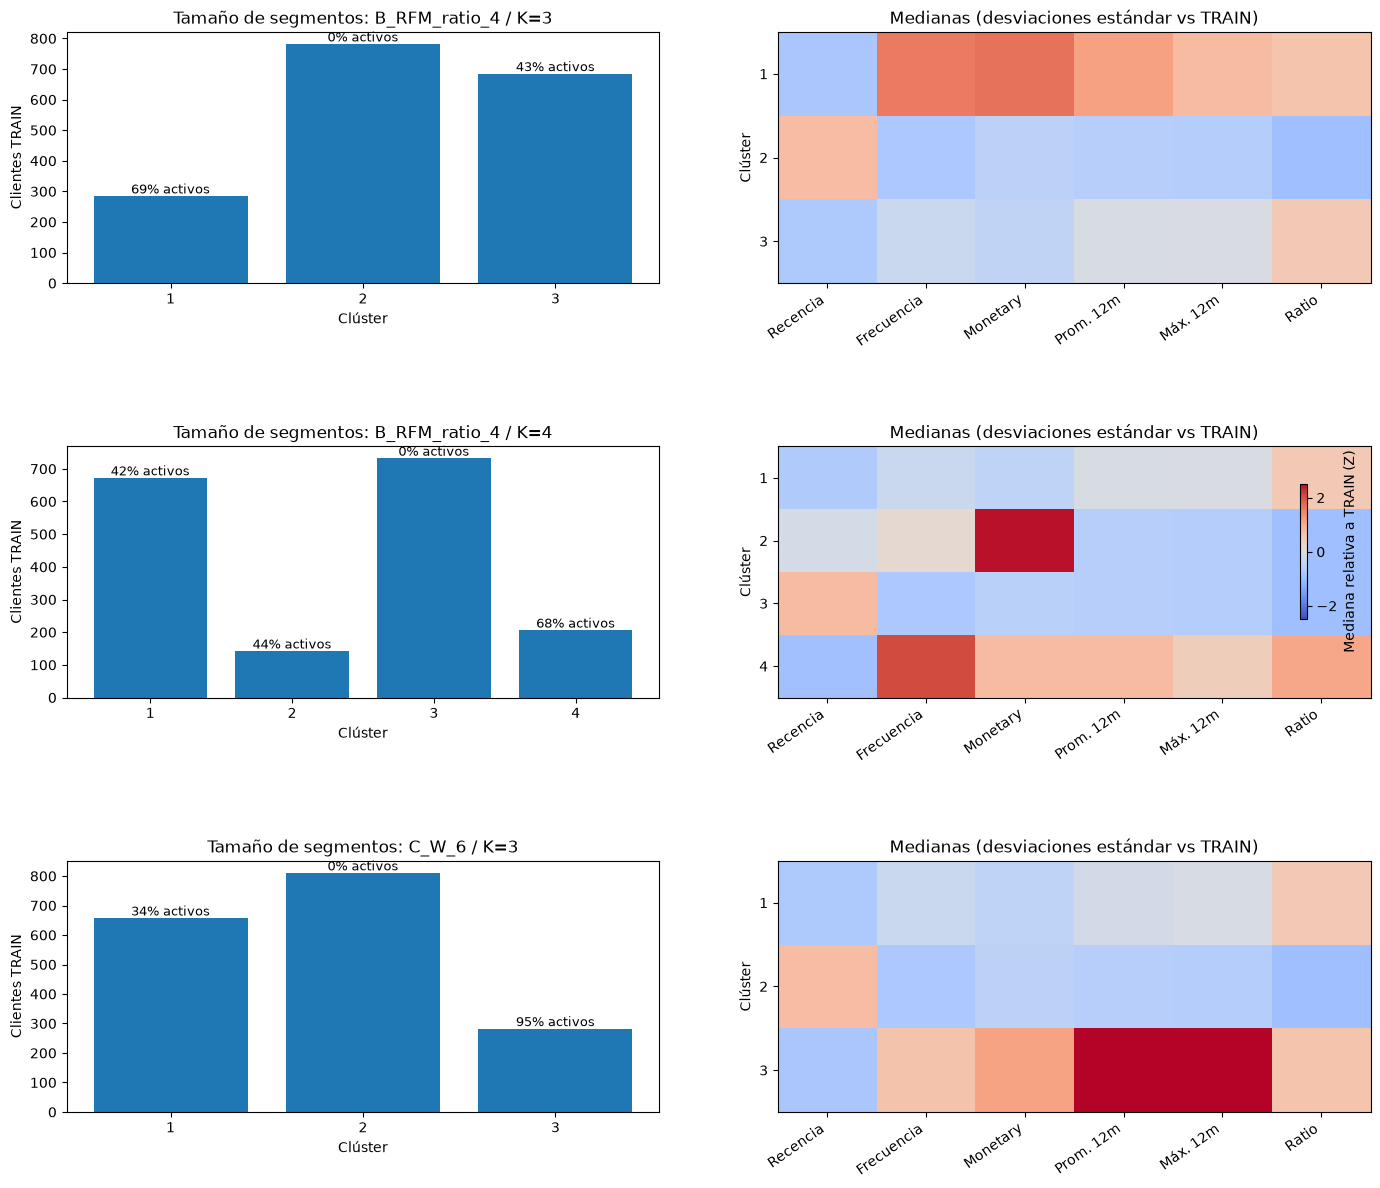

In [6]:
# Perfil visual de los tres candidatos prioritarios B3, B4, C3.
PRIORITARIOS = [("B_RFM_ratio_4",3),("B_RFM_ratio_4",4),("C_W_6",3)]
media6=train[SEIS_VARIABLES].mean()
sd6=train[SEIS_VARIABLES].std(ddof=1)
fig, axs=plt.subplots(len(PRIORITARIOS),2,figsize=(16,4.5*len(PRIORITARIOS)))
for i,(conf,k) in enumerate(PRIORITARIOS):
    p=perfiles_candidatos.loc[(perfiles_candidatos.configuracion==conf)&(perfiles_candidatos.k==k)].sort_values("cluster")
    axs[i,0].bar(p.cluster.astype(str),p.n_clientes)
    axs[i,0].set_title(f"Tamaño de segmentos: {conf} / K={k}")
    axs[i,0].set_ylabel("Clientes TRAIN")
    axs[i,0].set_xlabel("Clúster")
    for xx,yy in zip(range(len(p)),p.pct_activos_12m):
        axs[i,0].text(xx,float(p.n_clientes.iloc[xx])+8,f"{yy:.0f}% activos",ha="center",fontsize=9)
    mat=p[[f"{v}_mediana" for v in SEIS_VARIABLES]].to_numpy(dtype=float)
    mat=(mat-media6.to_numpy())/sd6.to_numpy()
    im=axs[i,1].imshow(mat,aspect="auto",cmap="coolwarm",vmin=-2.5,vmax=2.5)
    axs[i,1].set_yticks(range(len(p)),p.cluster.astype(str))
    axs[i,1].set_xticks(range(len(SEIS_VARIABLES)),
                         ["Recencia","Frecuencia","Monetary","Prom. 12m","Máx. 12m","Ratio"],rotation=35,ha="right")
    axs[i,1].set_title("Medianas (desviaciones estándar vs TRAIN)")
    axs[i,1].set_ylabel("Clúster")
fig.colorbar(im,ax=axs[:,1].tolist(),fraction=.012,pad=.01,label="Mediana relativa a TRAIN (Z)")
fig.subplots_adjust(hspace=.65,right=.94,bottom=.08)
fig.savefig(SALIDAS/"perfiles_visuales_B3_B4_C3.png",dpi=170,bbox_inches="tight")
plt.show()

## 6. Tabla integradora de evidencia (solo si están presentes los CSV anteriores)

Se integran *sin promediar* las métricas, los valores de ARI/Jaccard de las 300 repeticiones al 80%, la sensibilidad a `log1p` y la diferencia de Silhouette respecto a la permutación condicionada por actividad. El archivo queda listo para discutir la elección, pero **no construye un ranking automático**. Si no encuentra un archivo, deja sus columnas sin completar.

In [7]:
def buscar_resultado(nombre):
    candidatos_rutas=[CARPETA_SALIDA/nombre,Path.cwd()/nombre,
        CARPETA_SALIDA/f"resultados_kmeans_python{TAG}"/nombre,
        CARPETA_SALIDA/f"resultados_kmeans_sensibilidad{TAG}"/nombre,
        CARPETA_SALIDA/f"resultados_estructura_kmeans{TAG}"/nombre]
    encontrado=next((p for p in candidatos_rutas if p.is_file()),None)
    if encontrado is None:
        # Búsqueda recursiva solo en carpetas de resultados con el mismo TAG (evita mezclar umbrales).
        encontrado=next(CARPETA_SALIDA.glob(f"*{TAG}*/**/{nombre}"),None)
    return encontrado

evidencia=metricas_candidatos.copy()
fuentes=[]

ruta=buscar_resultado("estabilidad_resumen_por_fraccion_y_repeticiones.csv")
if ruta:
    e=pd.read_csv(ruta)
    e=e.loc[np.isclose(e.fraccion.astype(float),.8)].sort_values("n_repeticiones")
    e=e.groupby(["configuracion","k"],as_index=False).tail(1)
    cols=["configuracion","k","n_repeticiones","ARI_media","ARI_p05","Jaccard_min_cluster"]
    evidencia=evidencia.merge(e[cols],on=["configuracion","k"],how="left",validate="one_to_one")
    fuentes.append(str(ruta))

ruta=buscar_resultado("sensibilidad_kmeans_K_seleccionados.csv")
if ruta:
    s=pd.read_csv(ruta)
    filas=[]
    for (conf,k) in CANDIDATOS:
        pref="B" if conf=="B_RFM_ratio_4" else ("C" if conf=="C_W_6" else None)
        x=s.loc[(s.familia==pref)&(s.k==k)&(s.escenario==f"{pref}_log1p_gasto")] if pref else s.iloc[:0]
        filas.append({"configuracion":conf,"k":k,"ARI_log1p_vs_original":float(x.ARI_vs_referencia.iloc[0]) if len(x) else np.nan})
    evidencia=evidencia.merge(pd.DataFrame(filas),on=["configuracion","k"],how="left",validate="one_to_one")
    fuentes.append(str(ruta))

ruta=buscar_resultado("comparacion_silhouette_vs_referencias.csv")
if ruta:
    r=pd.read_csv(ruta)
    r=r.loc[r.referencia=="permutacion_estratificada",["configuracion","k","delta_silhouette","p_MC_exploratorio"]]
    evidencia=evidencia.merge(r.rename(columns={"delta_silhouette":"delta_silueta_ref_actividad"}),
                              on=["configuracion","k"],how="left",validate="one_to_one")
    fuentes.append(str(ruta))

evidencia.to_csv(SALIDAS/"tabla_integrada_evidencia_candidatos.csv",index=False)
print("Fuentes integradas:")
for fuente in fuentes: print(" •",fuente)
if not fuentes:
    print("No se encontraron otros CSV. No se altera la segmentación; solo falta integrar evidencia.")
display(evidencia.round(4))

Fuentes integradas:
 • c:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_kmeans_python_min80\estabilidad_multifraccion_50_100_200_300\estabilidad_resumen_por_fraccion_y_repeticiones.csv


,configuracion,k,n_variables,silhouette_train,davies_bouldin_train,calinski_harabasz_train,inercia_train,min_cluster,min_cluster_pct,alerta_menor_3pct,tamanos,n_repeticiones,ARI_media,ARI_p05,Jaccard_min_cluster
0,A_RFM_3,2,3,0.4465,1.0698,1115.6402,3207.9219,402,22.9452,False,1350;402,300,0.9821,0.9356,0.9825
1,B_RFM_ratio_4,3,4,0.4453,0.9323,1377.5799,2719.7072,285,16.2671,False,285;782;685,300,0.9836,0.9608,0.9577
2,B_RFM_ratio_4,4,4,0.4621,0.9421,1279.8011,2191.1774,142,8.1050,False,672;142;732;206,300,0.9911,0.9783,0.9540
3,C_W_6,2,6,0.4597,1.0398,1258.3955,6111.3972,415,23.6872,False,415;1337,300,0.9635,0.8751,0.9663
4,C_W_6,3,6,0.4436,0.9188,1470.4132,3918.0542,283,16.1530,False,658;811;283,300,0.9962,0.9795,0.9897
5,C_W_6,5,6,0.4501,1.0158,1281.6059,2670.2824,138,7.8767,False,220;678;560;156;138,300,0.9897,0.9690,0.9581


## 7. Fijar el modelo y exportar la segmentación de los clientes de T1 (TRAIN)

En `ETAPA="comparar"` se guardan los perfiles y asignaciones de los seis candidatos, **sin declarar todavía una partición definitiva**.

Después de examinar calidad, sensibilidad, estabilidad, evidencia de estructura e interpretación comercial, cambia `ETAPA="finalizar"` y fija explícitamente `MODELO_ELEGIDO`.

La salida final contiene el `response_id`, su etiqueta de clúster, la distancia al centroide, los perfiles de W y los centroides en unidades originales de W. No se necesita W_test.

In [8]:
if ETAPA == "comparar":
    print("ETAPA='comparar': seis segmentaciones de clientes TRAIN (T1) exportadas.")
    print("Antes de finalizar, revisa especialmente:")
    print("  1) tamaños, medianas y actividad reciente de B3, B4 y C3;")
    print("  2) si el cuarto clúster de B4 describe un perfil comercial adicional;")
    print("  3) si C3 separa principalmente clientes activos e inactivos;")
    print("  4) tabla_integrada_evidencia_candidatos.csv")
    print("Para fijar: ETAPA='finalizar' y MODELO_ELEGIDO=(nombre, K).")
else:
    conf, k = MODELO_ELEGIDO
    ajuste = ajustes[(conf, k)]
    DESTINO = SALIDAS / f"modelo_final__{conf}_K{k}"
    DESTINO.mkdir(parents=True, exist_ok=True)

    clientes = datos_etiquetados(train, ajuste, "TRAIN_T1")
    asignaciones = clientes[["response_id", "configuracion", "k", "cluster", "distancia_centroide_z"]]
    asignaciones.to_csv(DESTINO / "clusters_clientes_T1_TRAIN.csv", index=False)
    clientes.to_csv(DESTINO / "clientes_T1_TRAIN_con_cluster_y_W.csv", index=False)
    perfil_resumido(clientes).to_csv(DESTINO / "perfiles_segmentos_T1.csv", index=False)
    perfil_detallado(clientes).to_csv(DESTINO / "perfiles_segmentos_T1_detallados.csv", index=False)

    parametros = pd.DataFrame({
        "variable": ajuste["variables"],
        "media_train": ajuste["media"],
        "sd_train_ddof1": ajuste["sd"],
    })
    parametros.to_csv(DESTINO / "parametros_escalado_train.csv", index=False)
    centroides = pd.DataFrame(
        ajuste["modelo"].cluster_centers_ * ajuste["sd"] + ajuste["media"],
        columns=ajuste["variables"],
    )
    centroides.insert(0, "cluster", np.arange(1, k + 1))
    centroides.to_csv(DESTINO / "centroides_en_unidades_W.csv", index=False)

    tamanos = (clientes.groupby("cluster")["response_id"]
               .size().rename("n_clientes").reset_index())
    tamanos["porcentaje"] = 100 * tamanos.n_clientes / len(clientes)
    tamanos.to_csv(DESTINO / "tamanos_segmentos_T1.csv", index=False)

    with open(DESTINO / "metadatos_segmentacion.json", "w", encoding="utf-8") as out:
        json.dump({
            "configuracion": conf,
            "k": int(k),
            "variables": ajuste["variables"],
            "seed": SEMILLA,
            "n_init": N_INIT,
            "max_iter": MAX_ITER,
            "escalado": "Z-score ddof=1 calculado sobre TRAIN",
            "n_clientes_train_t1": len(train),
            "procedencia": "W winsorizada en R; clientes del TRAIN de Pogit; variables transaccionales T1",
            "advertencia": "La cohorte fue filtrada en R utilizando también un criterio de exclusión en T2",
            "nota": "La selección del modelo se realizó considerando exclusivamente los resultados de TRAIN",
        }, out, indent=2, ensure_ascii=False)
    try:
        import joblib
        joblib.dump({
            "kmeans": ajuste["modelo"],
            "variables": ajuste["variables"],
            "media_train": ajuste["media"],
            "sd_train_ddof1": ajuste["sd"],
        }, DESTINO / "modelo_kmeans_y_escalado.joblib")
        print("Modelo y escalado guardados.")
    except ImportError:
        print("No se encontró joblib. Los centroides y parámetros se guardaron en CSV.")

    print("\nSEGMENTACION FINAL DE CLIENTES T1 (TRAIN):", conf, "K=", k)
    print("Clientes:", len(clientes))
    print("Archivos guardados en:", DESTINO.resolve())
    display(tamanos)


Modelo y escalado guardados.

SEGMENTACION FINAL DE CLIENTES T1 (TRAIN): B_RFM_ratio_4 K= 4
Clientes: 1752
Archivos guardados en: C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\cluster_tag\cluster_tag\resultados_segmentacion_T1_train_min80\modelo_final__B_RFM_ratio_4_K4


,cluster,n_clientes,porcentaje
0,1,672,38.356164
1,2,142,8.105023
2,3,732,41.780822
3,4,206,11.757991


## 8. Archivos que debes revisar

**Primera ejecución (`ETAPA="comparar"`):**
- `perfiles_train_seis_candidatos.csv`: tamaños, actividad reciente y perfiles de las seis variables para cada candidato.
- `asignaciones_train_seis_candidatos.csv`: etiquetas por `response_id` para comparar soluciones.
- `tabla_integrada_evidencia_candidatos.csv`: calidad interna y evidencia complementaria cuando encuentra los CSV previos.
- `cruce_B_RFM_ratio_4_K3_vs_B_RFM_ratio_4_K4_conteos.csv` y `perfiles_visuales_B3_B4_C3.png`: diferencias entre B3, B4 y C3.

**Segunda ejecución (`ETAPA="finalizar"`, tras justificar el modelo):**
- `modelo_final__.../clusters_clientes_T1_TRAIN.csv`: asignación definitiva por cliente.
- `modelo_final__.../clientes_T1_TRAIN_con_cluster_y_W.csv`: datos de T1 y clúster.
- `modelo_final__.../perfiles_segmentos_T1.csv`: caracterización comercial de los segmentos.
- `modelo_final__.../centroides_en_unidades_W.csv`: centroides interpretables en las unidades originales de W.

**Importante:** el resultado segmenta únicamente los clientes de TRAIN utilizando compras de T1. No hay validación TEST ni pronóstico de ShoW, SioW o PoW. Las etiquetas son categorías descriptivas, no valores de predicción.
